# AUC and tPeak comparisons

Reads the AUC table saved by `auc_from_hdf5` and the tPeak table saved by `tpeak_from_hdf5`, and compares them in two ways:
- **Section 4:** conditions compared within a compartment (`plot_metric_by_genotype`). Each condition is compared with the control (Welch t-test or Mann–Whitney U, Holm-corrected).
- **Section 5:** compartments compared within a neuron type (`plot_metric_by_compartment`). Kruskal–Wallis (or Mann–Whitney U for two compartments), then pairwise Mann–Whitney U tests with Holm correction, shown as brackets.

Both functions take the name of the column to plot, so the same function is used for AUC and for tPeak.

Both tables are brought into the same form, one row per neuron, with the columns `genotype`, `series_id`, `subfolder` (compartment, written M1 … M10, Lo1, Lo4) and `trace_i`:
- AUC table: `AUC_ca`, `AUC_hylight`, `AUC_ratio`.
- tPeak table: one column per measure and sensor, for example `tpeak_s_ca`, `tpeak_s_hylight`, `peak_dff_hylight` and `t_first_depolarization_s_ca`. tPeak is NaN for non-responders, and those neurons are left out of the plots.

**How to use:** set the two CSV paths in section 1, then run all cells. The conditions, control and colors for section 4 are set at the start of that section.

In [1]:
from pathlib import Path
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import transforms as mtransforms
from matplotlib.lines import Line2D
from scipy import stats

## 1. Settings

In [89]:
# AUC table saved by auc_from_hdf5 (section 8 of that notebook).
AUC_CSV = Path("your/path/here/cc_lowpass-4hz_AUC_zerocross_final.csv")

# tPeak table saved by tpeak_from_hdf5 (section 8 of that notebook).
TPEAK_CSV = Path("your/path/here/cc_lowpass-4hz_tpeak_final.csv")

## 2. Load the tables

In [90]:
COMPARTMENT_NAMES = {
    "m1": "M1", "m2": "M2", "m3": "M3", "m5": "M5", "m8": "M8",
    "m9": "M9", "m10": "M10", "lo1": "Lo1", "lo4": "Lo4",
}


def _standardize_columns(df):
    """
    Rename the columns written by auc_from_hdf5 / tpeak_from_hdf5 to the names
    used by the plot functions, and write compartments as M1 ... M10, Lo1, Lo4.
    """
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    df = df.rename(columns={
        "Genotype": "genotype",
        "Series": "series_id",
        "Compartment": "subfolder",
        "Trace": "trace_i",
        "Measurement": "sensor",
    })

    for col in ["genotype", "series_id", "subfolder"]:
        df[col] = df[col].astype(str).str.strip()

    df["subfolder"] = (
        df["subfolder"].str.lower().map(COMPARTMENT_NAMES).fillna(df["subfolder"])
    )
    return df


def load_auc_csv(path):
    """
    AUC table from auc_from_hdf5: one row per neuron with
    AUC_ca, AUC_hylight and AUC_ratio.
    """
    df = _standardize_columns(pd.read_csv(path))
    for col in ["AUC_ca", "AUC_hylight", "AUC_ratio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


TPEAK_MEASURES = ["tpeak_s", "peak_dff", "t_first_depolarization_s"]


def load_tpeak_csv(path, measures=TPEAK_MEASURES):
    """
    tPeak table from tpeak_from_hdf5 (one row per neuron and sensor),
    turned into one row per neuron with a column per measure and sensor:
    tpeak_s_ca, tpeak_s_hylight, peak_dff_ca, ...
    """
    long_df = _standardize_columns(pd.read_csv(path))
    long_df["sensor"] = long_df["sensor"].astype(str).str.strip().str.lower()

    measures = [m for m in measures if m in long_df.columns]
    for m in measures:
        long_df[m] = pd.to_numeric(long_df[m], errors="coerce")

    wide = long_df.pivot(
        index=["genotype", "series_id", "subfolder", "trace_i"],
        columns="sensor",
        values=measures,
    )
    wide.columns = [f"{measure}_{sensor}" for measure, sensor in wide.columns]
    return wide.reset_index()


def count_flies_and_neurons(df, value_col):
    """Flies and neurons with a finite value in value_col, per condition and compartment."""
    d = df[np.isfinite(pd.to_numeric(df[value_col], errors="coerce"))]
    return (
        d.groupby(["genotype", "subfolder"])
        .agg(flies=("series_id", "nunique"), neurons=(value_col, "size"))
        .reset_index()
    )

In [91]:
auc_df = load_auc_csv(AUC_CSV)
tpeak_df = load_tpeak_csv(TPEAK_CSV)

print("AUC columns:  ", [c for c in auc_df.columns if c.startswith("AUC")])
print("tPeak columns:", [c for c in tpeak_df.columns if c not in ("genotype", "series_id", "subfolder", "trace_i")])
print("Conditions:   ", sorted(set(auc_df["genotype"]) | set(tpeak_df["genotype"])))
print("Compartments: ", sorted(set(auc_df["subfolder"]) | set(tpeak_df["subfolder"])))

AUC columns:   ['AUC_ca', 'AUC_hylight', 'AUC_ratio']
tPeak columns: ['tpeak_s_ca', 'tpeak_s_hylight', 'peak_dff_ca', 'peak_dff_hylight', 't_first_depolarization_s_ca', 't_first_depolarization_s_hylight']
Conditions:    ['postcc', 'precc']
Compartments:  ['M9']


Number of flies and neurons per condition and compartment. For tPeak, only responders (neurons with a tPeak) are counted:

In [92]:
count_flies_and_neurons(auc_df, "AUC_ratio")

,genotype,subfolder,flies,neurons
0,postcc,M9,10,46
1,precc,M9,6,21


In [93]:
count_flies_and_neurons(tpeak_df, "tpeak_s_hylight")

,genotype,subfolder,flies,neurons
0,postcc,M9,10,45
1,precc,M9,6,21


## 3. Plot functions

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import transforms as mtransforms

def plot_metric_by_genotype(
    data,
    value_col="AUC_hylight",
    genotype_order=None,
    subfolder_order=None,
    genotypes=None,
    subfolders=None,
    colors=None,
    color_by="subfolder",
    control_genotype="+Sugar",
    show_points=True,
    show_sem=True,
    show_legend=True,
    jitter_width=0.025,
    subfolder_offset_width=0.12,
    x_spacing=0.60,
    x_margin=0.18,
    box_aspect=None,
    point_size=20,
    point_alpha=0.45,
    mean_marker_size=6,
    mean_marker_edgewidth=0.8,
    figsize=(3.2, 3.5),
    dpi=300,
    ylabel=None,
    title=None,
    ylim=None,
    xlim=None,
    savepath=None,
    # stats options
    show_stats=True,
    stats_test="welch",
    p_adjust="holm",
    alpha=0.05,
    show_ns=False,
    stats_y_start=0.98,
    stats_y_step=0.065,
    stats_fontsize=12,
    labelsize=12,
    ylabelsize=12,
):
    """
    Plot one value per neuron (an AUC or a tPeak column) by genotype, with
    the mean ± SEM of each group, and compare each genotype to the control.

    x-axis:
        genotype

    optional overlay/color:
        subfolder (compartment), for example M2/M9/Lo1

    value_col:
        Column to plot, for example "AUC_ca", "AUC_hylight", "AUC_ratio",
        "tpeak_s_ca", "tpeak_s_hylight" or "t_first_depolarization_s_ca".
        Rows where this column is not a finite number (for example NaN tPeak
        values of non-responders) are left out.

    Stats:
        For each selected subfolder, compare each genotype to control_genotype
        within that same subfolder (Welch t-test or Mann-Whitney U), with Holm
        correction across all comparisons in the plot.

        control_genotype can be:
            "control"                         one control condition
            ["control", "control-RNAi"]       controls pooled
            {"pfk-RNAi": "control-RNAi"}      a separate control per genotype

    Names in genotype_order, subfolder_order, genotypes, subfolders and the
    keys of colors are matched without regard to capitalization.

    Important spacing options:
        x_spacing:
            Controls distance between genotype ticks.
            Smaller values bring genotype ticks closer together.

        x_margin:
            Controls left/right padding around plotted groups.
            Smaller values make the x-axis frame tighter.

        box_aspect:
            If None, the plot frame is allowed to be non-square.
            If set to 1, the plotting area is forced square.

    Returns
    -------
    fig, ax, summary, stats_df
    """

    d = data.copy()
    d.columns = [str(c).strip() for c in d.columns]

    required_cols = {"genotype", "subfolder", value_col}
    missing = required_cols - set(d.columns)
    if missing:
        raise ValueError(
            f"data is missing required columns: {sorted(missing)}\n"
            f"Available columns:\n{list(d.columns)}"
        )

    d["genotype"] = d["genotype"].astype(str).str.strip()
    d["subfolder"] = d["subfolder"].astype(str).str.strip()
    d[value_col] = pd.to_numeric(d[value_col], errors="coerce")
    d = d[np.isfinite(d[value_col])].copy()

    # Optional filtering
    if genotypes is not None:
        genotype_set = {str(g).lower() for g in genotypes}
        d = d[d["genotype"].astype(str).str.lower().isin(genotype_set)].copy()

    if subfolders is not None:
        subfolder_set = {str(s).lower() for s in subfolders}
        d = d[d["subfolder"].astype(str).str.lower().isin(subfolder_set)].copy()

    if d.empty:
        raise ValueError("No rows left after filtering. Check genotypes/subfolders.")

    # Determine genotype order
    if genotype_order is None:
        genotype_order = list(pd.unique(d["genotype"]))

    present_genotypes = {str(x).lower(): x for x in d["genotype"].unique()}
    genotype_order = [
        present_genotypes[str(x).strip().lower()]
        for x in genotype_order
        if str(x).strip().lower() in present_genotypes
    ]

    if len(genotype_order) == 0:
        raise ValueError("None of the requested genotypes are present after filtering.")

    # Determine subfolder order
    if subfolder_order is None:
        subfolder_order = list(pd.unique(d["subfolder"]))

    present_subfolders = {str(x).lower(): x for x in d["subfolder"].unique()}
    subfolder_order = [
        present_subfolders[str(x).strip().lower()]
        for x in subfolder_order
        if str(x).strip().lower() in present_subfolders
    ]

    if len(subfolder_order) == 0:
        raise ValueError("None of the requested subfolders are present after filtering.")

    if color_by not in ["subfolder", "genotype"]:
        raise ValueError("color_by must be 'subfolder' or 'genotype'.")

    if x_spacing <= 0:
        raise ValueError("x_spacing must be > 0.")

    if x_margin < 0:
        raise ValueError("x_margin must be >= 0.")

    # Color logic
    if colors is None:
        if color_by == "subfolder":
            color_map = {
                "M1": "#440154",
                "M2": "#31688e",
                "M3": "#440154",
                "M5": "#46327e",
                "M8": "#365c8d",
                "M9": "#2E6F8E",
                "M10": "#277f8e",
                "Lo1": "#1f9e89",
                "Lo4": "#35b779",
            }
        else:
            color_map = {
                "+Sugar": "#1f9e89",
                "-Sugar": "#31688e",
                "+Sugar+NaN3": "#35b779",
                "CTR": "black",
                "PFKRi": "#440154",
                "TNT": "#2E6F8E",
                "AMPKRi": "#1f9e89",
            }
    elif isinstance(colors, dict):
        color_map = colors
    elif isinstance(colors, (list, tuple)):
        color_keys = subfolder_order if color_by == "subfolder" else genotype_order
        if len(colors) < len(color_keys):
            raise ValueError("colors list has fewer colors than plotted groups.")
        color_map = dict(zip(color_keys, colors))
    else:
        raise TypeError("colors must be None, a dict, list, or tuple.")

    color_map_lower = {str(k).strip().lower(): v for k, v in color_map.items()}

    def _color_for(key):
        if key in color_map:
            return color_map[key]
        return color_map_lower.get(str(key).strip().lower(), "black")

    # X positions = genotypes
    # Smaller x_spacing truly brings ticks closer together.
    genotype_to_x = {g: i * x_spacing for i, g in enumerate(genotype_order)}

    # Offsets = subfolders, so multiple compartments can be overlaid per genotype
    if len(subfolder_order) > 1:
        offsets = np.linspace(
            -subfolder_offset_width,
            subfolder_offset_width,
            len(subfolder_order),
        )
    else:
        offsets = [0]

    subfolder_to_offset = dict(zip(subfolder_order, offsets))

    summary = (
        d.groupby(["genotype", "subfolder"], as_index=False)
        .agg(
            n=(value_col, "count"),
            mean_value=(value_col, "mean"),
            sem_value=(value_col, "sem"),
        )
    )

    def _p_to_stars(p):
        if not np.isfinite(p):
            return ""
        if p < 0.0001:
            return "****"
        if p < 0.001:
            return "***"
        if p < 0.01:
            return "**"
        if p < alpha:
            return "*"
        return "ns"

    def _holm_adjust(pvals):
        pvals = np.asarray(pvals, dtype=float)
        adjusted = np.full_like(pvals, np.nan, dtype=float)

        valid = np.isfinite(pvals)
        p = pvals[valid]

        if len(p) == 0:
            return adjusted

        order = np.argsort(p)
        adjusted_valid = np.empty_like(p, dtype=float)

        previous = 0.0
        m = len(p)

        for rank, idx in enumerate(order):
            value = (m - rank) * p[idx]
            value = max(previous, value)
            value = min(value, 1.0)
            adjusted_valid[idx] = value
            previous = value

        adjusted[valid] = adjusted_valid
        return adjusted
    
    def _calculate_stats():
        try:
            from scipy import stats
        except ImportError:
            raise ImportError(
                "scipy is required for stats. Install scipy or set show_stats=False."
            )

        def _as_list(x):
            if x is None:
                return []
            if isinstance(x, (list, tuple, set)):
                return [str(v).strip() for v in x]
            return [str(x).strip()]

        genotype_set = set(d["genotype"])

        # ------------------------------------------------------------
        # Control logic
        # ------------------------------------------------------------
        # Option 1:
        #   control_genotype = "+Sugar"
        #   every non-control genotype is compared to "+Sugar"
        #
        # Option 2:
        #   control_genotype = ["+Sugar", "-Sugar"]
        #   every non-control genotype is compared to pooled controls
        #
        # Option 3:
        #   control_genotype = {
        #       "+Sugar+NaN3": "+Sugar",
        #       "-Sugar+NaN3": "-Sugar",
        #   }
        #   each genotype is compared to its assigned control
        # ------------------------------------------------------------

        if isinstance(control_genotype, dict):
            control_lookup = {
                str(k).strip(): _as_list(v)
                for k, v in control_genotype.items()
            }

            all_controls = set()
            for vals in control_lookup.values():
                all_controls.update(vals)

            missing_controls = sorted(all_controls - genotype_set)
            if missing_controls:
                print(
                    "[warn] Some requested control genotypes were not found: "
                    f"{missing_controls}"
                )

            def _controls_for_genotype(genotype):
                return control_lookup.get(genotype, [])

            compare_only_mapped_genotypes = True

        else:
            default_controls = _as_list(control_genotype)
            all_controls = set(default_controls)

            missing_controls = sorted(all_controls - genotype_set)
            if missing_controls:
                print(
                    "[warn] Some requested control genotypes were not found: "
                    f"{missing_controls}"
                )

            def _controls_for_genotype(genotype):
                return default_controls

            compare_only_mapped_genotypes = False

        stat_rows = []

        for subfolder in subfolder_order:
            for genotype in genotype_order:

                # Do not compare controls against themselves.
                if genotype in all_controls:
                    continue

                # If using a dict, only calculate stats for explicitly mapped genotypes.
                if compare_only_mapped_genotypes and genotype not in control_lookup:
                    continue

                ctrl_genotypes = _controls_for_genotype(genotype)

                if len(ctrl_genotypes) == 0:
                    continue

                ctrl_vals = d[
                    (d["genotype"].isin(ctrl_genotypes))
                    & (d["subfolder"] == subfolder)
                ][value_col].dropna().to_numpy(dtype=float)

                test_vals = d[
                    (d["genotype"] == genotype)
                    & (d["subfolder"] == subfolder)
                ][value_col].dropna().to_numpy(dtype=float)

                if len(ctrl_vals) < 2 or len(test_vals) < 2:
                    p_raw = np.nan
                    stat_value = np.nan
                else:
                    if stats_test.lower() in ["welch", "welch_t", "ttest", "t-test"]:
                        res = stats.ttest_ind(
                            test_vals,
                            ctrl_vals,
                            equal_var=False,
                            nan_policy="omit",
                        )
                        stat_value = res.statistic
                        p_raw = res.pvalue

                    elif stats_test.lower() in ["mannwhitney", "mann-whitney", "mwu"]:
                        res = stats.mannwhitneyu(
                            test_vals,
                            ctrl_vals,
                            alternative="two-sided",
                        )
                        stat_value = res.statistic
                        p_raw = res.pvalue

                    else:
                        raise ValueError("stats_test must be 'welch' or 'mannwhitney'.")

                stat_rows.append(
                    {
                        "subfolder": subfolder,
                        "genotype": genotype,
                        "control_genotype": ", ".join(ctrl_genotypes),
                        "n_control": len(ctrl_vals),
                        "n_genotype": len(test_vals),
                        "mean_control": np.nanmean(ctrl_vals) if len(ctrl_vals) else np.nan,
                        "mean_genotype": np.nanmean(test_vals) if len(test_vals) else np.nan,
                        "test": stats_test,
                        "statistic": stat_value,
                        "p_raw": p_raw,
                    }
                )

        stats_df = pd.DataFrame(stat_rows)

        if len(stats_df) == 0:
            return stats_df

        if p_adjust is None:
            stats_df["p_adj"] = stats_df["p_raw"]
            stats_df["p_adjust_method"] = "none"
        elif str(p_adjust).lower() == "holm":
            stats_df["p_adj"] = _holm_adjust(stats_df["p_raw"].to_numpy(dtype=float))
            stats_df["p_adjust_method"] = "holm"
        else:
            raise ValueError("p_adjust must be 'holm' or None.")

        stats_df["stars"] = stats_df["p_adj"].apply(_p_to_stars)

        return stats_df
   

    stats_df = _calculate_stats() if show_stats else pd.DataFrame()

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    rng = np.random.default_rng(0)

    # Plot points and means
    for subfolder in subfolder_order:
        offset = subfolder_to_offset[subfolder]

        for genotype in genotype_order:
            gd = d[
                (d["genotype"] == genotype)
                & (d["subfolder"] == subfolder)
            ].copy()

            gs = summary[
                (summary["genotype"] == genotype)
                & (summary["subfolder"] == subfolder)
            ].copy()

            if gd.empty:
                continue

            x = genotype_to_x[genotype] + offset

            if color_by == "subfolder":
                color_key = subfolder
            else:
                color_key = genotype

            color = _color_for(color_key)

            if show_points:
                jitter = rng.normal(0, jitter_width, size=len(gd))

                ax.scatter(
                    np.full(len(gd), x) + jitter,
                    gd[value_col],
                    s=point_size,
                    color=color,
                    alpha=point_alpha,
                    linewidth=0,
                    zorder=1,
                )

            if not gs.empty:
                mean_val = gs["mean_value"].iloc[0]
                sem_val = gs["sem_value"].iloc[0]

                if show_sem:
                    ax.errorbar(
                        x,
                        mean_val,
                        yerr=sem_val,
                        fmt="o",
                        color=color,
                        markerfacecolor=color,
                        markeredgecolor="black",
                        markeredgewidth=mean_marker_edgewidth,
                        markersize=mean_marker_size,
                        capsize=3,
                        linewidth=1.0,
                        zorder=3,
                    )
                else:
                    ax.plot(
                        x,
                        mean_val,
                        "o",
                        color=color,
                        markerfacecolor=color,
                        markeredgecolor="black",
                        markeredgewidth=mean_marker_edgewidth,
                        markersize=mean_marker_size,
                        zorder=3,
                    )

    # Legend handles
    if show_legend:
        legend_keys = subfolder_order if color_by == "subfolder" else genotype_order

        for key in legend_keys:
            ax.scatter(
                [],
                [],
                color=_color_for(key),
                label=key,
                s=point_size,
                alpha=0.9,
            )

        ax.legend(frameon=False, fontsize=8, title=color_by)

    # Significance stars
    if show_stats and len(stats_df) > 0:
        text_transform = mtransforms.blended_transform_factory(
            ax.transData,
            ax.transAxes,
        )

        subfolder_to_star_row = {
            sf: i for i, sf in enumerate(subfolder_order)
        }

        for _, row in stats_df.iterrows():
            genotype = row["genotype"]
            subfolder = row["subfolder"]
            stars = row["stars"]

            if stars == "":
                continue

            if stars == "ns" and not show_ns:
                continue

            if genotype not in genotype_to_x:
                continue

            x = genotype_to_x[genotype] + subfolder_to_offset.get(subfolder, 0)

            y = stats_y_start - (
                subfolder_to_star_row.get(subfolder, 0) * stats_y_step
            )

            if color_by == "subfolder":
                color_key = subfolder
                
            else:
                color_key = genotype

            ax.text(
                x,
                y,
                stars,
                #color=_color_for(color_key),
                color = 'black',
                ha="center",
                va="top",
                fontsize=stats_fontsize,
                fontweight="bold",
                transform=text_transform,
                clip_on=False,
                zorder=10,
            )

    ax.set_xticks(list(genotype_to_x.values()))
    ax.set_xticklabels(genotype_order, rotation=45, ha="right")

    if ylabel is None:
        ylabel = value_col

    ax.set_ylabel(
    ylabel,
    fontsize=ylabelsize,
    labelpad=1,
    )

    if title is None:
        title = f"{value_col} by genotype"

    ax.set_title(title)

    if ylim is not None:
        ax.set_ylim(ylim)

    # Tight x-axis frame
    if xlim is not None:
        ax.set_xlim(xlim)
    else:
        plotted_x_positions = []

        for genotype in genotype_order:
            for subfolder in subfolder_order:
                group_has_data = not d[
                    (d["genotype"] == genotype)
                    & (d["subfolder"] == subfolder)
                ].empty

                if group_has_data:
                    plotted_x_positions.append(
                        genotype_to_x[genotype] + subfolder_to_offset.get(subfolder, 0)
                    )

        if len(plotted_x_positions) > 0:
            xmin = min(plotted_x_positions) - x_margin
            xmax = max(plotted_x_positions) + x_margin
            ax.set_xlim(xmin, xmax)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="both", labelsize=labelsize)

    # Do not force a square frame unless explicitly requested.
    if box_aspect is not None:
        ax.set_box_aspect(box_aspect)

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    return fig, ax, summary, stats_df

In [95]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from matplotlib.lines import Line2D
from scipy import stats


def plot_metric_by_compartment(
    data,
    metric="AUC_ratio",

    # Data columns
    neuron_col="genotype",
    series_col="series_id",
    compartment_col="subfolder",
    trace_col="trace_i",

    # Ordering and colors
    compartments=(
        "M1",
        "M2",
        "M3",
        "M5",
        "M8",
        "M9",
        "M10",
        "Lo1",
        "Lo4",
    ),
    compartment_colors=None,
    neuron_order=None,
    genotype_order=None,  # alias for neuron_order

    # Figure
    figsize=None,
    dpi=300,

    # Individual points and mean ± SEM
    show_points=True,
    show_sem=True,
    point_size=20,
    point_alpha=0.45,
    jitter_width=0.025,
    mean_marker_size=6,
    mean_marker_edgewidth=0.8,
    capsize=3,
    sem_linewidth=1.0,
    seed=0,

    # X-axis spacing
    x_spacing=0.60,
    group_gap=0.65,
    x_margin=0.18,
    group_label_y=-0.28,
    show_group_dividers=True,
    divider_color="0.88",
    divider_linewidth=0.8,

    # Labels and axes
    labelsize=12,
    ylabelsize=12,
    titlesize=12,
    group_labelsize=11,
    compartment_label_rotation=45,
    box_aspect=None,
    ylim=None,
    xlim=None,

    # Optional legend
    show_legend=False,
    legend_fontsize=8,
    legend_title="Compartment",

    # Statistics
    alpha=0.05,
    annotate_pairs="significant",
    # Options:
    #   "significant"
    #   "all"
    #   None
    #   [("M1", "M5"), ("M5", "M9")]

    max_annotations_per_neuron=3,
    bracket_text="stars",  # "stars" or "p"
    bracket_fontsize=10,
    bracket_linewidth=0.8,

    # Significance bracket spacing
    bracket_height_frac=0.020,
    bracket_gap_frac=0.070,
    bracket_y_offset_frac=0.020,
    star_text_offset_frac=0.002,
    bracket_top_padding_frac=0.090,
    annotation_interval_pad=0.08,
    expand_ylim_for_annotations=True,

    # Labels and saving
    title=None,
    ylabel=None,
    save_path=None,
    savepath=None,
    verbose=True,
):
    """
    Plot one value per neuron (an AUC or a tPeak column) separately for each
    neuron type/genotype, with one x-axis position per compartment.

    metric:
        Column to plot, for example "AUC_ratio", "AUC_hylight",
        "tpeak_s_hylight" or "tpeak_s_ca". Rows where this column is not a
        finite number (for example NaN tPeak values of non-responders) are
        left out.

    Individual rows/traces are plotted as transparent points. The mean and
    SEM are overlaid for each neuron-compartment combination.

    Statistics
    ----------
    Within each neuron/genotype:

        2 compartments:
            Mann-Whitney U test

        More than 2 compartments:
            Kruskal-Wallis omnibus test

        Pairwise post hoc:
            Mann-Whitney U tests with Holm correction

    Returns
    -------
    plot_df, summary_df, stats_summary, pairwise_df, fig, ax
    """

    # ============================================================
    # Helpers
    # ============================================================

    def normalize_compartment(value):
        return str(value).strip().lower()

    def pretty_compartment_label(value):
        value = normalize_compartment(value)

        if value.startswith("lo"):
            return "Lo" + value[2:]

        if value.startswith("m"):
            return "M" + value[1:]

        return str(value)

    def calculate_sem(values):
        values = pd.Series(values).dropna()

        if len(values) > 1:
            return values.std(ddof=1) / np.sqrt(len(values))

        return np.nan

    def holm_correction(p_values):
        """
        Apply Holm correction while preserving NaN positions.
        """
        p_values = np.asarray(p_values, dtype=float)

        adjusted = np.full(
            p_values.shape,
            np.nan,
            dtype=float,
        )

        valid_mask = np.isfinite(p_values)
        valid_p_values = p_values[valid_mask]

        if len(valid_p_values) == 0:
            return adjusted

        order = np.argsort(valid_p_values)
        adjusted_valid = np.empty_like(valid_p_values)

        previous = 0.0
        number_of_tests = len(valid_p_values)

        for rank, original_index in enumerate(order):
            corrected_value = (
                number_of_tests - rank
            ) * valid_p_values[original_index]

            corrected_value = max(
                previous,
                corrected_value,
            )

            corrected_value = min(
                corrected_value,
                1.0,
            )

            adjusted_valid[original_index] = corrected_value
            previous = corrected_value

        adjusted[valid_mask] = adjusted_valid

        return adjusted

    def p_to_stars(p_value):
        if not np.isfinite(p_value):
            return ""

        if p_value < 0.0001:
            return "****"

        if p_value < 0.001:
            return "***"

        if p_value < 0.01:
            return "**"

        if p_value < alpha:
            return "*"

        return "ns"

    def p_to_text(p_value):
        if not np.isfinite(p_value):
            return ""

        if p_value < 0.0001:
            return "p<0.0001"

        return f"p={p_value:.3g}"

    def intervals_overlap(
        x1a,
        x2a,
        x1b,
        x2b,
        pad=0.08,
    ):
        """
        Return True when two horizontal bracket ranges overlap.
        """
        a_min, a_max = sorted([x1a, x2a])
        b_min, b_max = sorted([x1b, x2b])

        return not (
            (a_max + pad) < b_min
            or
            (b_max + pad) < a_min
        )

    def assign_bracket_levels(
        neuron_annotations,
        neuron,
        x_lookup,
    ):
        """
        Assign significance brackets to non-overlapping vertical levels.
        """
        candidates = []

        for _, annotation_row in neuron_annotations.iterrows():
            compartment_1 = annotation_row[
                "_compartment_key_1"
            ]

            compartment_2 = annotation_row[
                "_compartment_key_2"
            ]

            key_1 = (
                neuron,
                compartment_1,
            )

            key_2 = (
                neuron,
                compartment_2,
            )

            if key_1 not in x_lookup or key_2 not in x_lookup:
                continue

            x_1 = x_lookup[key_1]
            x_2 = x_lookup[key_2]

            x_min, x_max = sorted(
                [x_1, x_2]
            )

            candidate = annotation_row.to_dict()

            candidate["_x1"] = x_1
            candidate["_x2"] = x_2
            candidate["_x_min"] = x_min
            candidate["_x_max"] = x_max
            candidate["_span"] = x_max - x_min

            candidates.append(candidate)

        if len(candidates) == 0:
            return []

        # Leftmost comparisons first.
        # Longer comparisons from the same origin are prioritized.
        candidates = sorted(
            candidates,
            key=lambda candidate: (
                candidate["_x_min"],
                -candidate["_span"],
                (
                    candidate.get("p_holm", np.inf)
                    if pd.notna(
                        candidate.get(
                            "p_holm",
                            np.inf,
                        )
                    )
                    else np.inf
                ),
            ),
        )

        level_intervals = []
        placements = []

        for candidate in candidates:
            assigned_level = None

            for level_index, intervals in enumerate(
                level_intervals
            ):
                overlaps_existing = any(
                    intervals_overlap(
                        candidate["_x_min"],
                        candidate["_x_max"],
                        existing_x_min,
                        existing_x_max,
                        pad=annotation_interval_pad,
                    )
                    for (
                        existing_x_min,
                        existing_x_max,
                    ) in intervals
                )

                if not overlaps_existing:
                    assigned_level = level_index

                    intervals.append(
                        (
                            candidate["_x_min"],
                            candidate["_x_max"],
                        )
                    )

                    break

            if assigned_level is None:
                assigned_level = len(
                    level_intervals
                )

                level_intervals.append(
                    [
                        (
                            candidate["_x_min"],
                            candidate["_x_max"],
                        )
                    ]
                )

            candidate["_level"] = assigned_level
            placements.append(candidate)

        # Invert levels so high-priority comparisons appear highest.
        maximum_level = max(
            placement["_level"]
            for placement in placements
        )

        for placement in placements:
            placement["_level"] = (
                maximum_level
                - placement["_level"]
            )

        placements = sorted(
            placements,
            key=lambda placement: (
                placement["_level"],
                placement["_x_min"],
                -placement["_span"],
            ),
        )

        return placements

    def add_significance_bracket(
        axis,
        x_1,
        x_2,
        y,
        height,
        text,
        text_offset=0.0,
    ):
        axis.plot(
            [x_1, x_1, x_2, x_2],
            [
                y,
                y + height,
                y + height,
                y,
            ],
            linewidth=bracket_linewidth,
            color="black",
            clip_on=False,
            zorder=10,
        )

        axis.text(
            (x_1 + x_2) / 2,
            y + height + text_offset,
            text,
            ha="center",
            va="bottom",
            fontsize=bracket_fontsize,
            fontweight="bold",
            color="black",
            clip_on=False,
            zorder=11,
        )

    # ============================================================
    # Validate arguments
    # ============================================================

    if x_spacing <= 0:
        raise ValueError(
            "x_spacing must be greater than 0."
        )

    if group_gap < 0:
        raise ValueError(
            "group_gap must be greater than or equal to 0."
        )

    if x_margin < 0:
        raise ValueError(
            "x_margin must be greater than or equal to 0."
        )

    if bracket_text not in {
        "stars",
        "p",
    }:
        raise ValueError(
            "bracket_text must be 'stars' or 'p'."
        )

    if max_annotations_per_neuron is not None:
        if max_annotations_per_neuron < 1:
            raise ValueError(
                "max_annotations_per_neuron must be at least "
                "1 or None."
            )

    if isinstance(annotate_pairs, str):
        if annotate_pairs not in {
            "significant",
            "all",
        }:
            raise ValueError(
                "annotate_pairs must be 'significant', 'all', "
                "None, or a list of compartment pairs."
            )

    # ============================================================
    # Load the dataframe
    # ============================================================

    if isinstance(data, (str, Path)):
        df = pd.read_csv(
            data,
            sep=None,
            engine="python",
        )

    elif isinstance(data, pd.DataFrame):
        df = data.copy()

    else:
        raise TypeError(
            "data must be a file path or a pandas DataFrame."
        )

    df.columns = [
        str(column).strip()
        for column in df.columns
    ]

    # ============================================================
    # Validate required columns
    # ============================================================

    required_columns = [
        neuron_col,
        series_col,
        compartment_col,
        trace_col,
        metric,
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}\n\n"
            f"Available columns: {list(df.columns)}"
        )

    df[metric] = pd.to_numeric(
        df[metric],
        errors="coerce",
    )

    df = df[
        np.isfinite(df[metric])
    ].copy()

    if df.empty:
        raise ValueError(
            "No valid rows remain after removing non-finite "
            f"values from {metric!r}."
        )

    # ============================================================
    # Normalize and filter compartments
    # ============================================================

    requested_compartments = list(
        compartments
    )

    requested_keys = [
        normalize_compartment(compartment)
        for compartment in requested_compartments
    ]

    df["_compartment_key"] = (
        df[compartment_col]
        .apply(normalize_compartment)
    )

    available_compartments = sorted(
        pd.unique(
            df[compartment_col].astype(str)
        )
    )

    df = df[
        df["_compartment_key"].isin(
            requested_keys
        )
    ].copy()

    if df.empty:
        raise ValueError(
            "After compartment filtering, no rows remain.\n"
            f"Requested compartments: {requested_compartments}\n"
            f"Available compartments: {available_compartments}"
        )

    # ============================================================
    # Neuron order
    # ============================================================

    if (
        genotype_order is not None
        and neuron_order is None
    ):
        neuron_order = genotype_order

    df[neuron_col] = (
        df[neuron_col]
        .astype(str)
        .str.strip()
    )

    if neuron_order is None:
        neuron_order = list(
            pd.unique(df[neuron_col])
        )

    else:
        neuron_order = [
            str(neuron).strip()
            for neuron in neuron_order
        ]

    available_neurons = set(
        df[neuron_col]
    )

    neuron_order = [
        neuron
        for neuron in neuron_order
        if neuron in available_neurons
    ]

    df = df[
        df[neuron_col].isin(
            neuron_order
        )
    ].copy()

    if df.empty or len(neuron_order) == 0:
        raise ValueError(
            "No rows remain after neuron_order filtering.\n"
            f"Available values in {neuron_col!r}: "
            f"{sorted(available_neurons)}"
        )

    # ============================================================
    # Colors
    # ============================================================

    if compartment_colors is None:
        color_map = plt.get_cmap(
            "viridis"
        )

        color_positions = np.linspace(
            0,
            1,
            len(requested_keys),
        )

        compartment_colors = {
            compartment_key: mcolors.to_hex(
                color_map(position)
            )
            for compartment_key, position in zip(
                requested_keys,
                color_positions,
            )
        }

    else:
        compartment_colors = {
            normalize_compartment(key): value
            for key, value
            in compartment_colors.items()
        }

    # ============================================================
    # Plot dataframe
    # ============================================================

    plot_df = df.rename(
        columns={
            metric: "value",
        }
    ).copy()

    plot_df["_unit_id"] = (
        plot_df[neuron_col].astype(str)
        + "__"
        + plot_df[series_col].astype(str)
        + "__"
        + plot_df["_compartment_key"].astype(str)
        + "__trace"
        + plot_df[trace_col].astype(str)
    )

    # ============================================================
    # Build x-axis layout
    # ============================================================

    x_layout_rows = []
    group_centers = {}
    group_bounds = {}

    current_x = 0.0

    for neuron in neuron_order:
        neuron_df = plot_df[
            plot_df[neuron_col] == neuron
        ]

        if neuron_df.empty:
            continue

        available_keys = set(
            neuron_df["_compartment_key"]
        )

        present_keys = [
            compartment_key
            for compartment_key in requested_keys
            if compartment_key in available_keys
        ]

        if len(present_keys) == 0:
            continue

        group_x_values = []

        for compartment_key in present_keys:
            x_layout_rows.append(
                {
                    neuron_col: neuron,
                    "_compartment_key":
                        compartment_key,
                    "_compartment_label":
                        pretty_compartment_label(
                            compartment_key
                        ),
                    "x": current_x,
                }
            )

            group_x_values.append(
                current_x
            )

            current_x += x_spacing

        group_centers[neuron] = float(
            np.mean(group_x_values)
        )

        group_bounds[neuron] = (
            float(np.min(group_x_values)),
            float(np.max(group_x_values)),
        )

        current_x += group_gap

    x_layout_df = pd.DataFrame(
        x_layout_rows
    )

    if x_layout_df.empty:
        raise ValueError(
            "No neuron-compartment combinations remain to plot."
        )

    plot_df = plot_df.merge(
        x_layout_df,
        on=[
            neuron_col,
            "_compartment_key",
        ],
        how="inner",
    )

    # ============================================================
    # Summary dataframe
    # ============================================================

    summary_df = (
        plot_df
        .groupby(
            [
                neuron_col,
                "_compartment_key",
                "_compartment_label",
                "x",
            ],
            as_index=False,
        )
        .agg(
            mean_value=("value", "mean"),
            sem_value=("value", calculate_sem),
            n=("value", "count"),
        )
        .sort_values("x")
        .reset_index(drop=True)
    )

    # ============================================================
    # Statistics within each neuron
    # ============================================================

    stats_summary_rows = []
    pairwise_rows = []

    for neuron in neuron_order:
        neuron_df = plot_df[
            plot_df[neuron_col] == neuron
        ].copy()

        if neuron_df.empty:
            continue

        available_keys = set(
            neuron_df["_compartment_key"]
        )

        present_compartments = [
            compartment_key
            for compartment_key in requested_keys
            if compartment_key in available_keys
        ]

        if verbose:
            print(
                f"\nNeuron/genotype: {neuron}"
            )

            print(
                "Available compartments:",
                [
                    pretty_compartment_label(
                        compartment_key
                    )
                    for compartment_key
                    in present_compartments
                ],
            )

        if len(present_compartments) < 2:
            stats_summary_rows.append(
                {
                    neuron_col: neuron,
                    "metric": metric,
                    "test_family": "not run",
                    "omnibus_test": "not run",
                    "n_compartments":
                        len(present_compartments),
                    "reason":
                        "Fewer than 2 compartments present.",
                    "statistic": np.nan,
                    "p_value": np.nan,
                    "significant": False,
                }
            )

            continue

        groups = [
            neuron_df.loc[
                neuron_df["_compartment_key"]
                == compartment_key,
                "value",
            ]
            .dropna()
            .to_numpy(dtype=float)
            for compartment_key
            in present_compartments
        ]

        if len(groups) == 2:
            omnibus_result = stats.mannwhitneyu(
                groups[0],
                groups[1],
                alternative="two-sided",
            )

            omnibus_statistic = (
                omnibus_result.statistic
            )

            omnibus_p_value = (
                omnibus_result.pvalue
            )

            omnibus_test = "Mann-Whitney U"

        else:
            try:
                omnibus_result = stats.kruskal(
                    *groups
                )

                omnibus_statistic = (
                    omnibus_result.statistic
                )

                omnibus_p_value = (
                    omnibus_result.pvalue
                )

            except ValueError:
                # This can occur when every value is identical.
                omnibus_statistic = np.nan
                omnibus_p_value = np.nan

            omnibus_test = "Kruskal-Wallis"

        stats_summary_rows.append(
            {
                neuron_col: neuron,
                "metric": metric,
                "test_family": "unpaired",
                "omnibus_test": omnibus_test,
                "n_compartments":
                    len(present_compartments),
                "statistic":
                    omnibus_statistic,
                "p_value":
                    omnibus_p_value,
                "significant": (
                    omnibus_p_value < alpha
                    if np.isfinite(
                        omnibus_p_value
                    )
                    else False
                ),
            }
        )

        for compartment_1, compartment_2 in itertools.combinations(
            present_compartments,
            2,
        ):
            values_1 = neuron_df.loc[
                neuron_df["_compartment_key"]
                == compartment_1,
                "value",
            ].dropna().to_numpy(dtype=float)

            values_2 = neuron_df.loc[
                neuron_df["_compartment_key"]
                == compartment_2,
                "value",
            ].dropna().to_numpy(dtype=float)

            if (
                len(values_1) >= 1
                and len(values_2) >= 1
            ):
                pair_result = stats.mannwhitneyu(
                    values_1,
                    values_2,
                    alternative="two-sided",
                )

                pair_statistic = (
                    pair_result.statistic
                )

                pair_p_value = (
                    pair_result.pvalue
                )

            else:
                pair_statistic = np.nan
                pair_p_value = np.nan

            pairwise_rows.append(
                {
                    neuron_col: neuron,
                    "compartment_1":
                        pretty_compartment_label(
                            compartment_1
                        ),
                    "compartment_2":
                        pretty_compartment_label(
                            compartment_2
                        ),
                    "_compartment_key_1":
                        compartment_1,
                    "_compartment_key_2":
                        compartment_2,
                    "test": "Mann-Whitney U",
                    "n_1": len(values_1),
                    "n_2": len(values_2),
                    "statistic":
                        pair_statistic,
                    "p_raw":
                        pair_p_value,
                }
            )

    stats_summary = pd.DataFrame(
        stats_summary_rows
    )

    pairwise_df = pd.DataFrame(
        pairwise_rows
    )

    # ============================================================
    # Holm correction
    # ============================================================

    if not pairwise_df.empty:
        pairwise_df["p_holm"] = np.nan
        pairwise_df["significant"] = False
        pairwise_df["stars"] = ""
        pairwise_df["p_text"] = ""

        for neuron in (
            pairwise_df[neuron_col]
            .dropna()
            .unique()
        ):
            neuron_mask = (
                pairwise_df[neuron_col]
                == neuron
            )

            corrected_p_values = holm_correction(
                pairwise_df.loc[
                    neuron_mask,
                    "p_raw",
                ].to_numpy(dtype=float)
            )

            pairwise_df.loc[
                neuron_mask,
                "p_holm",
            ] = corrected_p_values

            pairwise_df.loc[
                neuron_mask,
                "significant",
            ] = corrected_p_values < alpha

            pairwise_df.loc[
                neuron_mask,
                "stars",
            ] = [
                p_to_stars(p_value)
                for p_value
                in corrected_p_values
            ]

            pairwise_df.loc[
                neuron_mask,
                "p_text",
            ] = [
                p_to_text(p_value)
                for p_value
                in corrected_p_values
            ]

    if verbose:
        print("\nOmnibus tests:")
        print(stats_summary)

        print("\nPairwise tests:")
        print(pairwise_df)

    # ============================================================
    # Select significance annotations
    # ============================================================

    annotation_rows = []

    if (
        annotate_pairs is not None
        and not pairwise_df.empty
    ):
        for neuron in neuron_order:
            neuron_pairwise = pairwise_df[
                pairwise_df[neuron_col]
                == neuron
            ].copy()

            if neuron_pairwise.empty:
                continue

            if annotate_pairs == "significant":
                annotation_subset = neuron_pairwise[
                    neuron_pairwise["p_holm"]
                    < alpha
                ].copy()

            elif annotate_pairs == "all":
                annotation_subset = (
                    neuron_pairwise.copy()
                )

            else:
                wanted_pairs = {
                    tuple(
                        sorted(
                            [
                                normalize_compartment(
                                    compartment_1
                                ),
                                normalize_compartment(
                                    compartment_2
                                ),
                            ]
                        )
                    )
                    for (
                        compartment_1,
                        compartment_2,
                    ) in annotate_pairs
                }

                neuron_pairwise[
                    "_normalized_pair"
                ] = neuron_pairwise.apply(
                    lambda row: tuple(
                        sorted(
                            [
                                row[
                                    "_compartment_key_1"
                                ],
                                row[
                                    "_compartment_key_2"
                                ],
                            ]
                        )
                    ),
                    axis=1,
                )

                annotation_subset = (
                    neuron_pairwise[
                        neuron_pairwise[
                            "_normalized_pair"
                        ].isin(wanted_pairs)
                    ].copy()
                )

            annotation_subset = (
                annotation_subset.sort_values(
                    "p_holm",
                    na_position="last",
                )
            )

            if max_annotations_per_neuron is not None:
                annotation_subset = (
                    annotation_subset.head(
                        max_annotations_per_neuron
                    )
                )

            annotation_rows.extend(
                annotation_subset.to_dict(
                    "records"
                )
            )

    annotation_df = pd.DataFrame(
        annotation_rows
    )

    # ============================================================
    # Assign bracket positions
    # ============================================================

    x_lookup = {
        (
            layout_row[neuron_col],
            layout_row["_compartment_key"],
        ): layout_row["x"]
        for _, layout_row
        in x_layout_df.iterrows()
    }

    bracket_placements_by_neuron = {}

    if not annotation_df.empty:
        for neuron in neuron_order:
            neuron_annotations = annotation_df[
                annotation_df[neuron_col]
                == neuron
            ]

            if neuron_annotations.empty:
                continue

            placements = assign_bracket_levels(
                neuron_annotations,
                neuron,
                x_lookup,
            )

            if len(placements) > 0:
                bracket_placements_by_neuron[
                    neuron
                ] = placements

    # ============================================================
    # Determine initial y-limits
    # ============================================================

    values = (
        plot_df["value"]
        .dropna()
        .to_numpy(dtype=float)
    )

    summary_upper = (
        summary_df["mean_value"]
        + summary_df["sem_value"].fillna(0)
    ).max()

    summary_lower = (
        summary_df["mean_value"]
        - summary_df["sem_value"].fillna(0)
    ).min()

    data_y_min = float(
        np.nanmin(
            [
                np.nanmin(values),
                summary_lower,
            ]
        )
    )

    data_y_max = float(
        np.nanmax(
            [
                np.nanmax(values),
                summary_upper,
            ]
        )
    )

    data_range = (
        data_y_max - data_y_min
    )

    if (
        not np.isfinite(data_range)
        or data_range <= 0
    ):
        data_range = max(
            abs(data_y_max),
            1.0,
        )

    if ylim is None:
        y_lower = (
            data_y_min
            - 0.08 * data_range
        )

        y_upper = (
            data_y_max
            + 0.16 * data_range
        )

    else:
        y_lower, y_upper = ylim

    if y_upper <= y_lower:
        raise ValueError(
            "ylim must be an increasing (lower, upper) pair."
        )

    y_span = y_upper - y_lower

    # ============================================================
    # Expand the y-axis for significance brackets
    # ============================================================

    if (
        expand_ylim_for_annotations
        and bracket_placements_by_neuron
    ):
        for _ in range(8):
            y_span = y_upper - y_lower

            bracket_height = (
                bracket_height_frac
                * y_span
            )

            bracket_gap = (
                bracket_gap_frac
                * y_span
            )

            bracket_step = (
                bracket_height
                + bracket_gap
            )

            text_offset = (
                star_text_offset_frac
                * y_span
            )

            required_upper = y_upper

            for neuron, placements in (
                bracket_placements_by_neuron.items()
            ):
                neuron_values = plot_df.loc[
                    plot_df[neuron_col]
                    == neuron,
                    "value",
                ].dropna().to_numpy(dtype=float)

                neuron_summary = summary_df[
                    summary_df[neuron_col]
                    == neuron
                ]

                neuron_summary_upper = (
                    neuron_summary["mean_value"]
                    + neuron_summary[
                        "sem_value"
                    ].fillna(0)
                ).max()

                neuron_y_max = float(
                    np.nanmax(
                        [
                            np.nanmax(
                                neuron_values
                            ),
                            neuron_summary_upper,
                        ]
                    )
                )

                maximum_level = max(
                    placement["_level"]
                    for placement in placements
                )

                base_y = (
                    neuron_y_max
                    + bracket_y_offset_frac
                    * y_span
                )

                needed_upper = (
                    base_y
                    + maximum_level
                    * bracket_step
                    + bracket_height
                    + text_offset
                    + bracket_top_padding_frac
                    * y_span
                )

                required_upper = max(
                    required_upper,
                    needed_upper,
                )

            if required_upper > y_upper:
                y_upper = required_upper
            else:
                break

        y_span = y_upper - y_lower

    # ============================================================
    # Figure size
    # ============================================================

    number_of_positions = len(
        x_layout_df
    )

    if figsize is None:
        figsize = (
            max(
                5.0,
                0.32 * number_of_positions,
            ),
            3.5,
        )

    # ============================================================
    # Create figure
    # ============================================================

    fig, ax = plt.subplots(
        figsize=figsize,
        dpi=dpi,
    )

    random_generator = (
        np.random.default_rng(seed)
    )

    # ============================================================
    # Plot individual points and mean ± SEM
    # ============================================================

    for _, summary_row in summary_df.iterrows():
        neuron = summary_row[
            neuron_col
        ]

        compartment_key = summary_row[
            "_compartment_key"
        ]

        x_position = summary_row["x"]

        color = compartment_colors.get(
            compartment_key,
            "black",
        )

        group_values = plot_df.loc[
            (
                plot_df[neuron_col]
                == neuron
            )
            & (
                plot_df["_compartment_key"]
                == compartment_key
            ),
            "value",
        ].dropna().to_numpy(dtype=float)

        if (
            show_points
            and len(group_values) > 0
        ):
            jitter = random_generator.normal(
                loc=0,
                scale=jitter_width,
                size=len(group_values),
            )

            ax.scatter(
                np.full(
                    len(group_values),
                    x_position,
                )
                + jitter,
                group_values,
                s=point_size,
                color=color,
                alpha=point_alpha,
                linewidth=0,
                zorder=1,
            )

        mean_value = summary_row[
            "mean_value"
        ]

        sem_value = summary_row[
            "sem_value"
        ]

        if show_sem:
            y_error = (
                0
                if pd.isna(sem_value)
                else sem_value
            )

            ax.errorbar(
                x_position,
                mean_value,
                yerr=y_error,
                fmt="o",
                color=color,
                markerfacecolor=color,
                markeredgecolor="black",
                markeredgewidth=(
                    mean_marker_edgewidth
                ),
                markersize=mean_marker_size,
                capsize=capsize,
                linewidth=sem_linewidth,
                zorder=3,
            )

        else:
            ax.plot(
                x_position,
                mean_value,
                "o",
                color=color,
                markerfacecolor=color,
                markeredgecolor="black",
                markeredgewidth=(
                    mean_marker_edgewidth
                ),
                markersize=mean_marker_size,
                zorder=3,
            )

    # ============================================================
    # Plot significance brackets
    # ============================================================

    if bracket_placements_by_neuron:
        bracket_height = (
            bracket_height_frac
            * y_span
        )

        bracket_gap = (
            bracket_gap_frac
            * y_span
        )

        bracket_step = (
            bracket_height
            + bracket_gap
        )

        text_offset = (
            star_text_offset_frac
            * y_span
        )

        for neuron, placements in (
            bracket_placements_by_neuron.items()
        ):
            neuron_values = plot_df.loc[
                plot_df[neuron_col]
                == neuron,
                "value",
            ].dropna().to_numpy(dtype=float)

            neuron_summary = summary_df[
                summary_df[neuron_col]
                == neuron
            ]

            neuron_summary_upper = (
                neuron_summary["mean_value"]
                + neuron_summary[
                    "sem_value"
                ].fillna(0)
            ).max()

            neuron_y_max = float(
                np.nanmax(
                    [
                        np.nanmax(
                            neuron_values
                        ),
                        neuron_summary_upper,
                    ]
                )
            )

            starting_y = (
                neuron_y_max
                + bracket_y_offset_frac
                * y_span
            )

            for placement in placements:
                if bracket_text == "p":
                    label = placement.get(
                        "p_text",
                        p_to_text(
                            placement["p_holm"]
                        ),
                    )

                else:
                    label = placement.get(
                        "stars",
                        p_to_stars(
                            placement["p_holm"]
                        ),
                    )

                if label == "":
                    continue

                y_position = (
                    starting_y
                    + placement["_level"]
                    * bracket_step
                )

                add_significance_bracket(
                    axis=ax,
                    x_1=placement["_x1"],
                    x_2=placement["_x2"],
                    y=y_position,
                    height=bracket_height,
                    text=label,
                    text_offset=text_offset,
                )

    # ============================================================
    # Compartment labels
    # ============================================================

    ax.set_xticks(
        x_layout_df["x"].to_numpy(
            dtype=float
        )
    )

    ax.set_xticklabels(
        x_layout_df[
            "_compartment_label"
        ],
        rotation=compartment_label_rotation,
        ha="right",
    )

    # ============================================================
    # Group dividing lines
    # ============================================================

    if show_group_dividers:
        plotted_neurons = [
            neuron
            for neuron in neuron_order
            if neuron in group_bounds
        ]

        for left_neuron, right_neuron in zip(
            plotted_neurons[:-1],
            plotted_neurons[1:],
        ):
            divider_x = (
                group_bounds[left_neuron][1]
                + group_bounds[right_neuron][0]
            ) / 2

            ax.axvline(
                divider_x,
                color=divider_color,
                linewidth=divider_linewidth,
                zorder=0,
            )

    # ============================================================
    # Optional legend
    # ============================================================

    if show_legend:
        plotted_compartment_keys = set(
            x_layout_df[
                "_compartment_key"
            ]
        )

        present_compartment_keys = [
            compartment_key
            for compartment_key in requested_keys
            if compartment_key
            in plotted_compartment_keys
        ]

        handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markerfacecolor=(
                    compartment_colors.get(
                        compartment_key,
                        "black",
                    )
                ),
                markeredgecolor="black",
                markeredgewidth=(
                    mean_marker_edgewidth
                ),
                markersize=mean_marker_size,
                label=pretty_compartment_label(
                    compartment_key
                ),
            )
            for compartment_key
            in present_compartment_keys
        ]

        ax.legend(
            handles=handles,
            frameon=False,
            fontsize=legend_fontsize,
            title=legend_title,
        )

    # ============================================================
    # Default labels
    # ============================================================

    if ylabel is None:
        ylabel = metric

    if title is None:
        title = ""

    # ============================================================
    # Axis appearance
    # ============================================================

    ax.set_ylabel(
        ylabel,
        fontsize=ylabelsize,
    )

    ax.set_xlabel("")

    ax.set_title(
        title,
        fontsize=titlesize,
    )

    ax.set_ylim(
        y_lower,
        y_upper,
    )

    if xlim is not None:
        ax.set_xlim(xlim)

    else:
        plotted_x = x_layout_df[
            "x"
        ].to_numpy(dtype=float)

        ax.set_xlim(
            plotted_x.min() - x_margin,
            plotted_x.max() + x_margin,
        )

    ax.spines["top"].set_visible(
        False
    )

    ax.spines["right"].set_visible(
        False
    )

    ax.tick_params(
        axis="both",
        labelsize=labelsize,
    )

    if box_aspect is not None:
        ax.set_box_aspect(
            box_aspect
        )

    fig.subplots_adjust(
        left=0.12,
        right=0.98,
        bottom=0.34,
        top=0.90,
    )

    # ============================================================
    # Save
    # ============================================================

    output_path = (
        savepath
        if savepath is not None
        else save_path
    )

    if output_path is not None:
        output_path = Path(
            output_path
        )

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        fig.savefig(
            output_path,
            dpi=dpi,
            bbox_inches="tight",
        )

    return (
        plot_df,
        summary_df,
        stats_summary,
        pairwise_df,
        fig,
        ax,
    )

In [96]:
def relabel_xticks(ax, label_map):
    """
    Replace displayed x-axis tick labels without changing the underlying data labels.
    """
    ticks = ax.get_xticks()
    labels = [tick.get_text() for tick in ax.get_xticklabels()]
    new_labels = [label_map.get(label, label) for label in labels]

    ax.set_xticks(ticks)
    ax.set_xticklabels(new_labels)

## 4. Conditions compared within a compartment
Set the conditions, the control and the colors here. `control` can be one condition, a list of conditions (pooled), or a dictionary that gives each condition its own control, for example `{"pfk-RNAi": "control-RNAi"}`.

In [100]:
genotypes = ["control", "control-RNAi", "acly-RNAi"]
control = ["control", "control-RNAi"] #for the screen

control = ["control", ]

genotypes = ['control', 'NaN3', 'SF', 'SF+NaN3', 'recovery']

# Colors for the HyLight/Ca ratio, Ca and HyLight plots.
condition_colors = {
    "control": "#000000",
    "control-RNAi": "#999999",
    "acly-RNAi": "#D3D3D3",
}
condition_colors_ca = {
    "control": "#000000",
    "control-RNAi": "#999999",
    "acly-RNAi": "#f768a1",
}
condition_colors_hylight = {
    "control": "#000000",
    "control-RNAi": "#999999",
    "acly-RNAi": "#78c679",
}

control = ["preBAY", ]
genotypes =["preBAY","postBAY" ]

control = ["precc", ]
genotypes =["precc","postcc" ]
# Optional shorter x-axis labels, applied with relabel_xticks(ax, condition_label_map).
condition_label_map = {}

# Compartment(s) to compare in.
compartments_to_plot = ["M9"]

### 4a. AUC

HyLight AUC:

,subfolder,genotype,control_genotype,n_control,n_genotype,mean_control,mean_genotype,test,statistic,p_raw,p_adj,p_adjust_method,stars
0,M9,postcc,precc,21,46,1.078696,0.644868,welch,-6.750216,5.722384e-08,5.722384e-08,holm,****


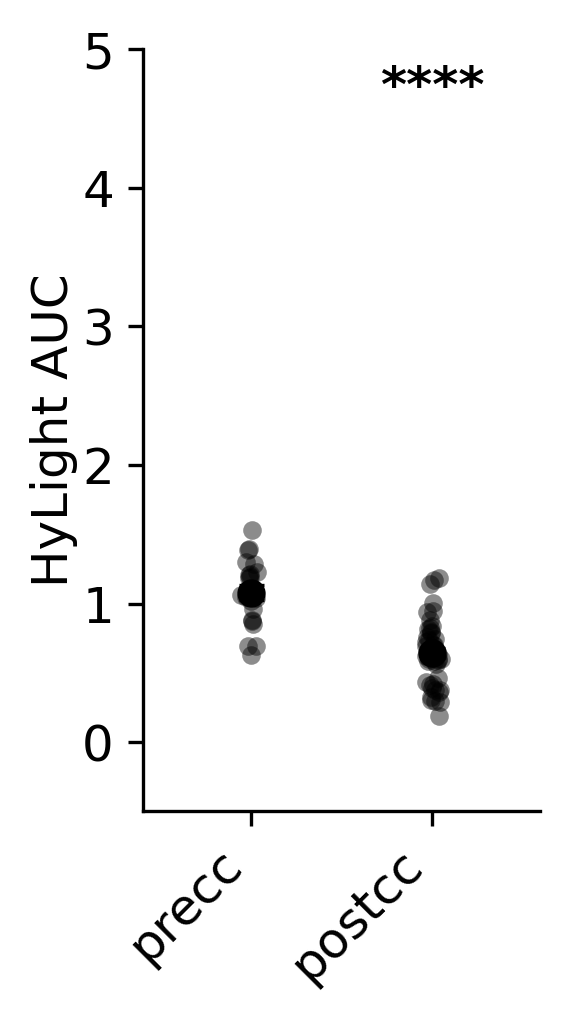

In [101]:
fig, ax, summary, stats_df = plot_metric_by_genotype(
    auc_df,
    value_col="AUC_hylight",
    genotype_order=genotypes,
    subfolder_order=["M2", "M9", "Lo1"],
    genotypes=genotypes,
    subfolders=compartments_to_plot,
    colors=condition_colors_hylight,
    color_by="genotype",
    control_genotype=control,
    ylabel="HyLight AUC",
    title="",
    show_stats=True,
    stats_test="welch",
    p_adjust="holm",
    show_legend=False,
    ylim=(-0.5, 5),
    stats_fontsize=12,
    labelsize=12,
    ylabelsize=12,
    jitter_width=0.005,
    x_spacing=0.2,
    x_margin=0.12,
    figsize=(2, 3.5),
    box_aspect=None,
)
stats_df

Ca (jRGECO1a) AUC:

,subfolder,genotype,control_genotype,n_control,n_genotype,mean_control,mean_genotype,test,statistic,p_raw,p_adj,p_adjust_method,stars
0,M9,postcc,precc,21,46,0.779307,0.778934,welch,-0.004387,0.99652,0.99652,holm,ns


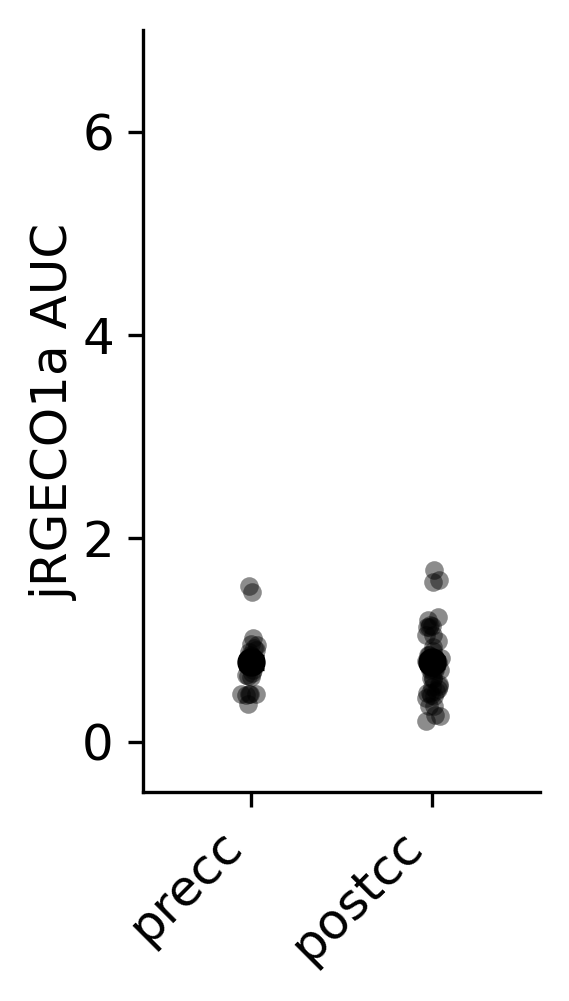

In [102]:
fig, ax, summary, stats_df = plot_metric_by_genotype(
    auc_df,
    value_col="AUC_ca",
    genotype_order=genotypes,
    subfolder_order=["M2", "M9", "Lo1"],
    genotypes=genotypes,
    subfolders=compartments_to_plot,
    colors=condition_colors_ca,
    color_by="genotype",
    control_genotype=control,
    ylabel="jRGECO1a AUC",
    title="",
    show_stats=True,
    stats_test="welch",
    p_adjust="holm",
    show_legend=False,
    ylim=(-0.5, 7),
    stats_fontsize=12,
    labelsize=12,
    ylabelsize=12,
    jitter_width=0.005,
    x_spacing=0.2,
    x_margin=0.12,
    figsize=(2, 3.5),
    box_aspect=None,
)
stats_df

HyLight AUC / Ca AUC:

,subfolder,genotype,control_genotype,n_control,n_genotype,mean_control,mean_genotype,test,statistic,p_raw,p_adj,p_adjust_method,stars
0,M9,postcc,precc,21,46,1.556834,0.936333,welch,-4.27968,0.000176,0.000176,holm,***


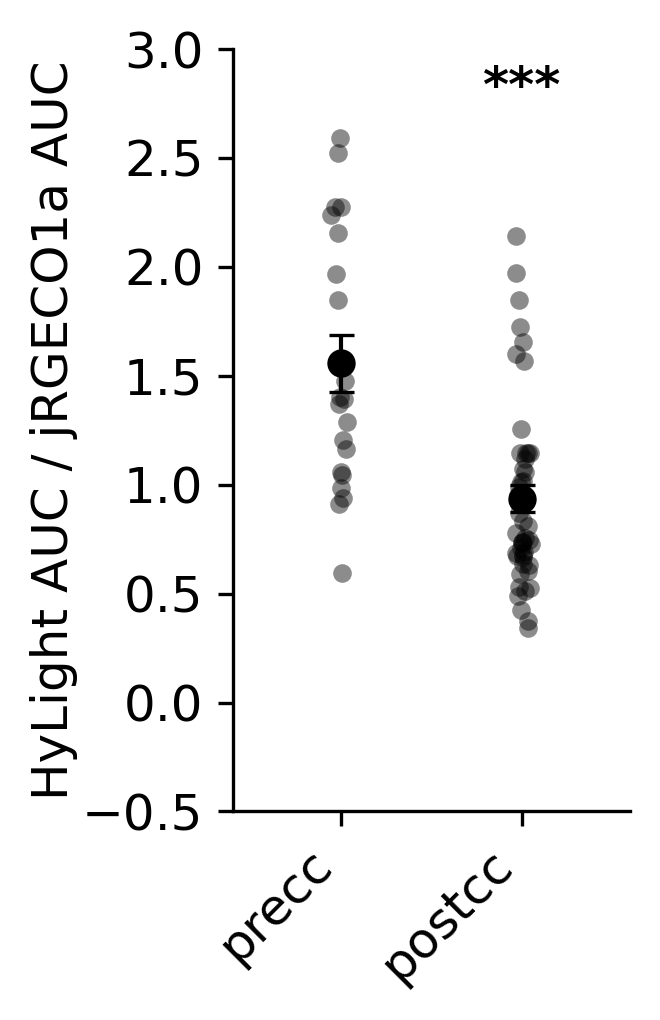

In [103]:
fig, ax, summary, stats_df = plot_metric_by_genotype(
    auc_df,
    value_col="AUC_ratio",
    genotype_order=genotypes,
    subfolder_order=["M2", "M9", "Lo1"],
    genotypes=genotypes,
    subfolders=compartments_to_plot,
    colors=condition_colors,
    color_by="genotype",
    control_genotype=control,
    ylabel="HyLight AUC / jRGECO1a AUC",
    title="",
    show_stats=True,
    stats_test="welch",
    p_adjust="holm",
    show_legend=False,
    ylim=(-0.5, 3),
    stats_fontsize=12,
    labelsize=12,
    ylabelsize=12,
    jitter_width=0.005,
    x_spacing=0.2,
    x_margin=0.12,
    figsize=(2.3, 3.5),
    box_aspect=None,
)
stats_df

### 4b. tPeak
The same function with a tPeak column. The tPeak search window in `tpeak_from_hdf5` ends 15 s after stimulus onset, so values are at most 15 s.

HyLight tPeak:

In [76]:
fig, ax, summary, stats_df = plot_metric_by_genotype(
    tpeak_df,
    value_col="tpeak_s_hylight",
    genotype_order=genotypes,
    subfolder_order=["M2", "M9", "Lo1"],
    genotypes=genotypes,
    subfolders=compartments_to_plot,
    colors=condition_colors_hylight,
    color_by="genotype",
    control_genotype=control,
    ylabel=r"HyLight $t_{\mathrm{peak}}$ (s)",
    title="",
    show_stats=True,
    stats_test="welch",
    p_adjust="holm",
    show_legend=False,
    ylim=(0, 16),
    stats_fontsize=12,
    labelsize=12,
    ylabelsize=12,
    jitter_width=0.01,
    x_spacing=0.2,
    x_margin=0.12,
    figsize=(2, 3.5),
    box_aspect=None,
)
stats_df

Ca (jRGECO1a) tPeak:

In [77]:
fig, ax, summary, stats_df = plot_metric_by_genotype(
    tpeak_df,
    value_col="tpeak_s_ca",
    genotype_order=genotypes,
    subfolder_order=["M2", "M9", "Lo1"],
    genotypes=genotypes,
    subfolders=compartments_to_plot,
    colors=condition_colors_ca,
    color_by="genotype",
    control_genotype=control,
    ylabel=r"jRGECO1a $t_{\mathrm{peak}}$ (s)",
    title="",
    show_stats=True,
    stats_test="welch",
    p_adjust="holm",
    show_legend=False,
    ylim=(0, 16),
    stats_fontsize=12,
    labelsize=12,
    ylabelsize=12,
    jitter_width=0.01,
    x_spacing=0.2,
    x_margin=0.12,
    figsize=(2, 3.5),
    box_aspect=None,
)
stats_df

## 5. Compartments compared within a neuron type
`neurons_to_plot` lists the values of the `genotype` column to plot (for the compartment data these are neuron types, such as `tm9`). Brackets show the significant pairwise differences (at most `max_annotations_per_neuron`).

In [78]:
compartment_colors = {
    "m1":  "#1f1f1f",
    "m2":  "#383838",
    "m3":  "#525252",
    "m5":  "#6b6b6b",
    "m8":  "#858585",
    "m9":  "#9e9e9e",
    "m10": "#b8b8b8",
    "lo1": "#d1d1d1",
    "lo4": "#e6e6e6",
}

all_compartments = ("m1", "m2", "m3", "m5", "m8", "m9", "m10", "lo1", "lo4")

neurons_to_plot = ["tm2"]

### 5a. AUC (HyLight AUC / Ca AUC)

In [79]:
(
    plot_df,
    summary_df,
    stats_summary,
    pairwise_df,
    fig,
    ax,
) = plot_metric_by_compartment(
    auc_df,
    metric="AUC_ratio",
    compartments=all_compartments,
    compartment_colors=compartment_colors,
    neuron_order=neurons_to_plot,
    ylabel="HyLight AUC / jRGECO1a AUC",
    title="",
    annotate_pairs="significant",
    max_annotations_per_neuron=3,
    show_legend=False,
    dpi=300,
    figsize=(3, 2.5),
    ylim=None,
    verbose=False,
    bracket_gap_frac=0.090,         # larger = brackets farther apart
    bracket_y_offset_frac=0.0920,   # smaller = first bracket closer to data
    star_text_offset_frac=0.0001,
    labelsize=9,
    ylabelsize=9,
    bracket_fontsize=10,
    jitter_width=0.005,
)

plt.show()
pairwise_df

### 5b. tPeak (HyLight)

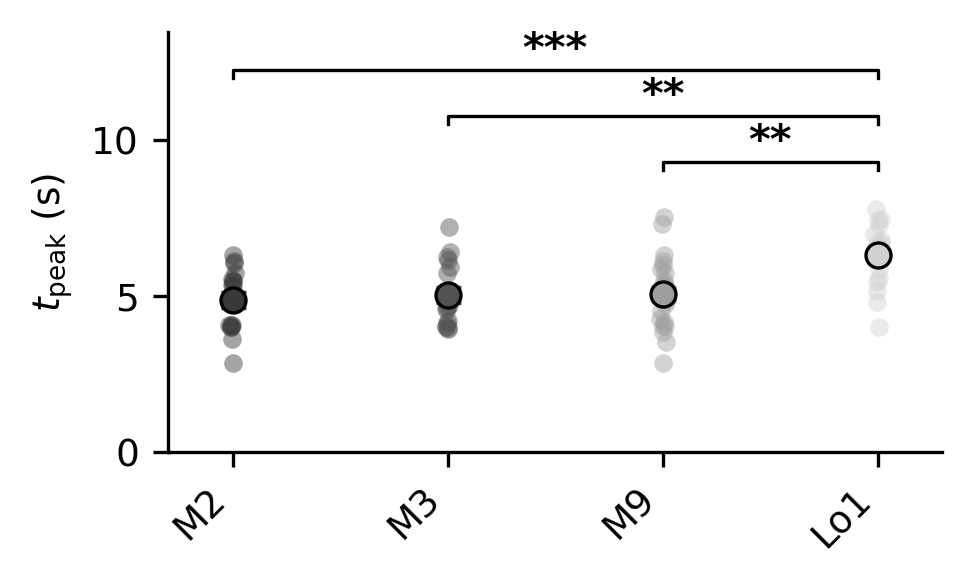

,genotype,compartment_1,compartment_2,_compartment_key_1,_compartment_key_2,test,n_1,n_2,statistic,p_raw,p_holm,significant,stars,p_text
0,tm2,M2,M3,m2,m3,Mann-Whitney U,16,16,114.5,0.624070,1.000000,False,ns,p=1
1,tm2,M2,M9,m2,m9,Mann-Whitney U,16,24,185.0,0.857550,1.000000,False,ns,p=1
2,tm2,M2,Lo1,m2,lo1,Mann-Whitney U,16,22,46.0,0.000129,0.000771,True,***,p=0.000771
3,tm2,M3,M9,m3,m9,Mann-Whitney U,16,24,179.0,0.729996,1.000000,False,ns,p=1
4,tm2,M3,Lo1,m3,lo1,Mann-Whitney U,16,22,60.0,0.000637,0.002549,True,**,p=0.00255
5,tm2,M9,Lo1,m9,lo1,Mann-Whitney U,24,22,96.0,0.000230,0.001150,True,**,p=0.00115


In [58]:
(
    plot_df,
    summary_df,
    stats_summary,
    pairwise_df,
    fig,
    ax,
) = plot_metric_by_compartment(
    tpeak_df,
    metric="tpeak_s_hylight",
    compartments=all_compartments,
    compartment_colors=compartment_colors,
    neuron_order=neurons_to_plot,
    ylabel=r"$t_{\mathrm{peak}}$ (s)",
    title="",
    annotate_pairs="significant",
    max_annotations_per_neuron=3,
    show_legend=False,
    dpi=300,
    figsize=(3, 2.5),
    ylim=(0, 2.4),
    verbose=False,
    bracket_gap_frac=0.090,         # larger = brackets farther apart
    bracket_y_offset_frac=0.0920,   # smaller = first bracket closer to data
    star_text_offset_frac=0.0001,
    labelsize=9,
    ylabelsize=9,
    bracket_fontsize=10,
    jitter_width=0.005,
)

plt.show()
pairwise_df

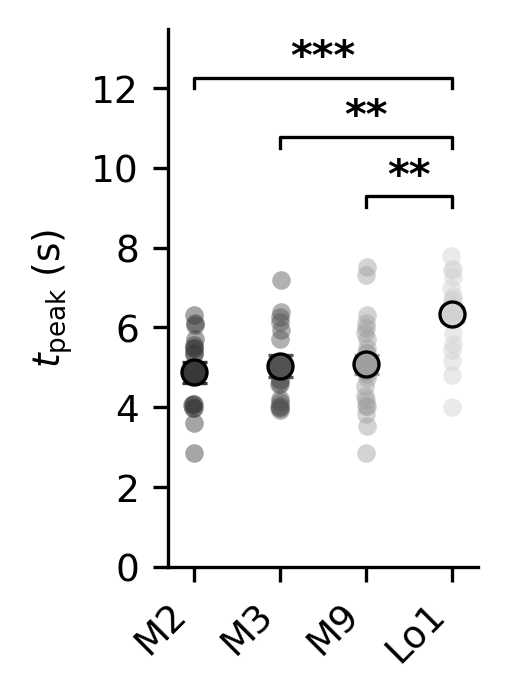

,genotype,compartment_1,compartment_2,_compartment_key_1,_compartment_key_2,test,n_1,n_2,statistic,p_raw,p_holm,significant,stars,p_text
0,tm2,M2,M3,m2,m3,Mann-Whitney U,16,16,114.5,0.624070,1.000000,False,ns,p=1
1,tm2,M2,M9,m2,m9,Mann-Whitney U,16,24,185.0,0.857550,1.000000,False,ns,p=1
2,tm2,M2,Lo1,m2,lo1,Mann-Whitney U,16,22,46.0,0.000129,0.000771,True,***,p=0.000771
3,tm2,M3,M9,m3,m9,Mann-Whitney U,16,24,179.0,0.729996,1.000000,False,ns,p=1
4,tm2,M3,Lo1,m3,lo1,Mann-Whitney U,16,22,60.0,0.000637,0.002549,True,**,p=0.00255
5,tm2,M9,Lo1,m9,lo1,Mann-Whitney U,24,22,96.0,0.000230,0.001150,True,**,p=0.00115


In [59]:
(
    plot_df,
    summary_df,
    stats_summary,
    pairwise_df,
    fig,
    ax,
) = plot_metric_by_compartment(
    tpeak_df,
    metric="tpeak_s_hylight",
    compartments=all_compartments,
    compartment_colors=compartment_colors,
    neuron_order=neurons_to_plot,
    ylabel=r"$t_{\mathrm{peak}}$ (s)",
    title="",
    annotate_pairs="significant",
    max_annotations_per_neuron=3,
    show_legend=False,
    dpi=300,
    figsize=(1.2, 3.2),
    ylim=(0, 11),
    verbose=False,
    bracket_gap_frac=0.090,         # larger = brackets farther apart
    bracket_y_offset_frac=0.0920,   # smaller = first bracket closer to data
    star_text_offset_frac=0.0001,
    labelsize=9,
    ylabelsize=9,
    bracket_fontsize=10,
    jitter_width=0.005,
)

plt.show()
pairwise_df

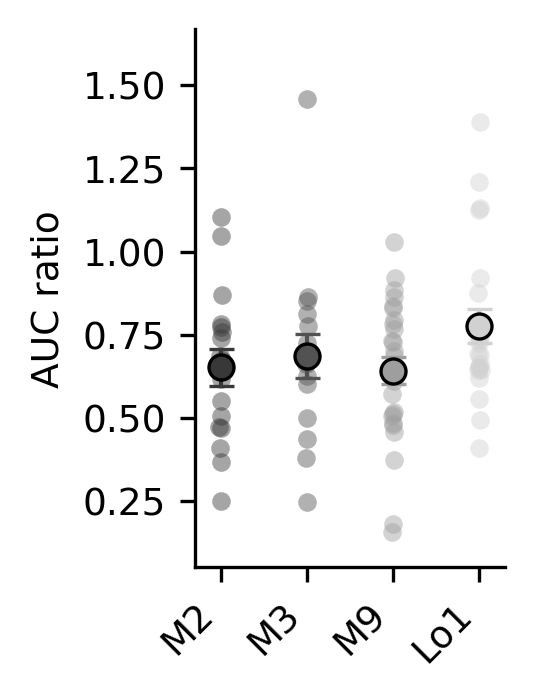

,genotype,compartment_1,compartment_2,_compartment_key_1,_compartment_key_2,test,n_1,n_2,statistic,p_raw,p_holm,significant,stars,p_text
0,tm2,M2,M3,m2,m3,Mann-Whitney U,17,16,129.0,0.814874,1.000000,False,ns,p=1
1,tm2,M2,M9,m2,m9,Mann-Whitney U,17,26,214.0,0.871731,1.000000,False,ns,p=1
2,tm2,M2,Lo1,m2,lo1,Mann-Whitney U,17,22,137.0,0.160933,0.965596,False,ns,p=0.966
3,tm2,M3,M9,m3,m9,Mann-Whitney U,16,26,212.0,0.927769,1.000000,False,ns,p=1
4,tm2,M3,Lo1,m3,lo1,Mann-Whitney U,16,22,144.0,0.351690,1.000000,False,ns,p=1
5,tm2,M9,Lo1,m9,lo1,Mann-Whitney U,26,22,218.0,0.162508,0.965596,False,ns,p=0.966


In [61]:
(
    plot_df,
    summary_df,
    stats_summary,
    pairwise_df,
    fig,
    ax,
) = plot_metric_by_compartment(
    auc_df,
    metric="AUC_ratio",
    compartments=all_compartments,
    compartment_colors=compartment_colors,
    neuron_order=neurons_to_plot,
    ylabel="AUC ratio",
    title="",
    annotate_pairs="significant",
    max_annotations_per_neuron=3,
    show_legend=False,
    dpi=300,
    figsize=(1.2, 3.2),
    ylim=None,
    verbose=False,
    bracket_gap_frac=0.090,         # larger = brackets farther apart
    bracket_y_offset_frac=0.0920,   # smaller = first bracket closer to data
    star_text_offset_frac=0.0001,
    labelsize=9,
    ylabelsize=9,
    bracket_fontsize=10,
    jitter_width=0.005,
)

plt.show()
pairwise_df